# 다음 영화 리뷰 데이터 분석

1. **데이터 로딩**
2. **텍스트 전처리**
3. **빈도수 계산**
4. **시각화**

## 1. 데이터 로딩

In [105]:
import pandas as pd
import numpy as np

datafile = '../data/daum_movie_review.csv'
df = pd.read_csv(datafile)

### 1-1. 데이터 확인

In [106]:
df.head()

,review,rating,date,title
0,돈 들인건 티가 나지만 보는 내내 하품만,1,2018.10.29,인피니티 워
1,몰입할수밖에 없다. 어렵게 생각할 필요없다. 내가 전투에 참여한듯 손에 땀이남.,10,2018.10.26,인피니티 워
2,이전 작품에 비해 더 화려하고 스케일도 커졌지만.... 전국 맛집의 음식들을 한데 ...,8,2018.10.24,인피니티 워
3,이 정도면 볼만하다고 할 수 있음!,8,2018.10.22,인피니티 워
4,재미있다,10,2018.10.20,인피니티 워


In [107]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14725 entries, 0 to 14724
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   review  14725 non-null  str  
 1   rating  14725 non-null  int64
 2   date    14725 non-null  str  
 3   title   14725 non-null  str  
dtypes: int64(1), str(3)
memory usage: 460.3 KB


## 2. 텍스트 전처리

In [108]:
%pip install konlpy

Note: you may need to restart the kernel to use updated packages.


### 2-1. 품사 태깅

In [109]:
# konlpy로 review 토큰화 (pos() : 품사 태깅, morphs() : 형태소만 추출, nouns() : 명사만 추출)
from konlpy.tag import Okt

tagger = Okt()
reviews = list(df.review)

pos_list = []
for review in reviews:
    tokens = tagger.pos(review) # pos() : 품사 태깅
    pos_list.append(tokens)

len(pos_list)

14725

In [110]:
pos_list[:1]

[[('돈', 'Noun'),
  ('들인건', 'Verb'),
  ('티', 'Noun'),
  ('가', 'Josa'),
  ('나', 'Noun'),
  ('지만', 'Josa'),
  ('보는', 'Verb'),
  ('내내', 'Noun'),
  ('하품', 'Noun'),
  ('만', 'Josa')]]

### 2-2. 불용어 제거

In [111]:
# 필요한 품사의 단어만 추출
my_tags = ['Noun', 'Verb', 'Adjective']
my_stopwords = ['영화', '것', '이', '더', '입니다', '그', '점', '수', '등', '점', '좀', '정도', '이런', '저런', '이거', '볼'
, '저거', '이제', '그냥', '진짜', '아주', '많이', '너무', '정말', '할', '돈', '내', '내', '말', '왜', '때', '꼭', '평점', '있는', '본']
result_list = []
for review in pos_list:
    for word, tag in review:
        if tag in my_tags and word not in my_stopwords:
            result_list.append(word)
result_list[:10]

['들인건', '티', '나', '보는', '내내', '하품', '몰입', '할수밖에', '없다', '어렵게']

## 3. 빈도수 계산

In [112]:
# counter 객체를 생성하여 사용

from collections import Counter

counter = Counter(result_list)
counter.most_common(20) #고빈도 단어 20위까지의 단어 추출

[('연기', 1293),
 ('감동', 1223),
 ('생각', 1027),
 ('배우', 847),
 ('사람', 819),
 ('스토리', 815),
 ('잘', 776),
 ('하는', 770),
 ('눈물', 737),
 ('보고', 709),
 ('최고', 682),
 ('재미', 641),
 ('마지막', 612),
 ('시간', 596),
 ('마동석', 556),
 ('광주', 530),
 ('윤계상', 517),
 ('기대', 516),
 ('내용', 494),
 ('장면', 438)]

In [113]:
count_list = counter.most_common(20)

## 4. 시각화

In [114]:
# matplotlib 한글 폰트 설정
import matplotlib.pyplot as plt
font_path = 'C:/Windows/Fonts/malgun.ttf'
from matplotlib import font_manager, rc
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

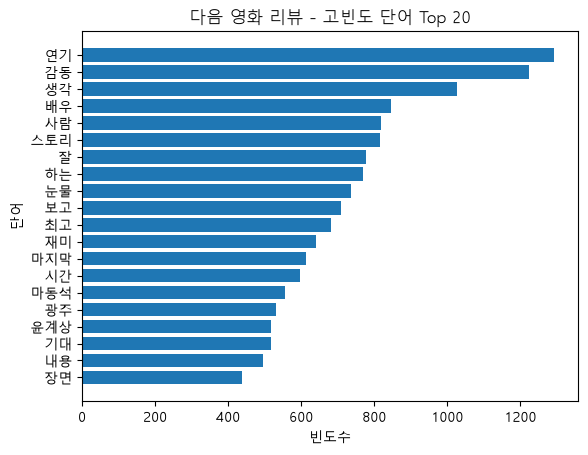

In [115]:
# 시각화 - 수평 막대 그래프
import matplotlib.pyplot as plt

# (1) 데이터 준비
x = [word for word, count in count_list]
y = [count for word, count in count_list]

# (2) 그래프 생성
plt.barh(x[::-1], y[::-1])

# (3) 필요 정보 추가
plt.title('다음 영화 리뷰 - 고빈도 단어 Top 20')
plt.xlabel('빈도수')
plt.ylabel('단어')

# (4) 그래프 출력
#plt.show()
plt.savefig('result/daum_movie_review_Top20.jpg') # 이미지 저장